In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

In [2]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [3]:
from pathlib import Path
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=str(Path.home() / ".cache" / "ml-notebooks" / "speech-commands"),
    batch_size=64,
    validation_split=0.3,
    seed=seed,
    output_sequence_length=16000,
    subset="both"
)

Found 6505 files belonging to 4 classes.


Using 4554 files for training.


Using 1951 files for validation.


In [4]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [5]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_spectrogram(waveform):
    spectrogram = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    spectrogram = tf.abs(spectrogram)
    spectrogram = spectrogram[..., tf.newaxis]
    return spectrogram

def make_spectrogram_ds(ds):
    return ds.map(
        map_func=lambda audio, label: (get_spectrogram(audio), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

In [6]:
# Squeeze audio
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

# Split data to 15% test and 15% validation
test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [7]:
# Convert waveform to spectrogram
train_spectrogram_ds = make_spectrogram_ds(train_ds)
val_spectrogram_ds = make_spectrogram_ds(val_ds)
test_spectrogram_ds = make_spectrogram_ds(test_ds)

In [8]:
# Create metadata for model (input_shape, num_label)
for example_spectrogram, example_spectrogram_label in train_spectrogram_ds.take(1):
    break

input_shape = example_spectrogram.shape[1:]
num_label=len(label)

In [9]:
# Create normalization layer
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_spectrogram_ds.map(
        map_func=lambda spec, label: spec
    )
)

In [10]:
# Create model
model = models.Sequential(
    [
        layers.Input(shape=input_shape),
        layers.Resizing(32, 32),
        norm_layer,
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(128, (1, 3), activation='relu'),  # same shape as the old Conv1D(128, 3) on 4-D input
        layers.MaxPooling2D(),
        layers.Dropout(0.5),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_label)
    ]
)

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 13, 128)    │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5376)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,376,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,402,887 (5.35 MB)

 Trainable params: 1,402,884 (5.35 MB)

 Non-trainable params: 3 (16.00 B)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_spectrogram_ds,
    validation_data=val_spectrogram_ds,
    epochs=8,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/8


C:\Users\jorda\Code\ml-notebooks\courses\speech-recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/72 ━━━━━━━━━━━━━━━━━━━━ 1:01 864ms/step - accuracy: 0.1250 - loss: 1.4476

 4/72 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3047 - loss: 1.3580   

 6/72 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3464 - loss: 1.3163

 8/72 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3867 - loss: 1.2773

... (188 outputs left out)

63/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9229 - loss: 0.2354

67/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9242 - loss: 0.2301

71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9243 - loss: 0.2275

72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9238 - loss: 0.2283 - val_accuracy: 0.9354 - val_loss: 0.1691


In [14]:
# Testing
for i, (spectrogram_batch, label_batch) in enumerate(test_spectrogram_ds):
    prediction = model.predict(spectrogram_batch)
    
    for j in range(len(label_batch)):
        true_index = label_batch[j].numpy()
        predicted_index = np.argmax(prediction[j])
        
        print(
            f"Batch: {i}, Data: {j} - Original Label: {label[true_index]} | Predicted Label: {label[predicted_index]}"
        )

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step 


Batch: 0, Data: 0 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 1 - Original Label: learn | Predicted Label: learn
Batch: 0, Data: 2 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 3 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 4 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 5 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 6 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 7 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 8 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 9 - Original Label: learn | Predicted Label: learn
Batch: 0, Data: 10 - Original Label: visual | Predicted Label: visual
Batch: 0, Data: 11 - Original Label: learn | Predicted Label: learn
Batch: 0, Data: 12 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 13 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 14 - Original Label: follow | Predic

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


Batch: 1, Data: 0 - Original Label: visual | Predicted Label: visual
Batch: 1, Data: 1 - Original Label: tree | Predicted Label: tree
Batch: 1, Data: 2 - Original Label: learn | Predicted Label: learn
Batch: 1, Data: 3 - Original Label: tree | Predicted Label: tree
Batch: 1, Data: 4 - Original Label: follow | Predicted Label: follow
Batch: 1, Data: 5 - Original Label: visual | Predicted Label: visual
Batch: 1, Data: 6 - Original Label: follow | Predicted Label: follow
Batch: 1, Data: 7 - Original Label: tree | Predicted Label: tree
Batch: 1, Data: 8 - Original Label: visual | Predicted Label: visual
Batch: 1, Data: 9 - Original Label: visual | Predicted Label: visual
Batch: 1, Data: 10 - Original Label: visual | Predicted Label: visual
Batch: 1, Data: 11 - Original Label: follow | Predicted Label: follow
Batch: 1, Data: 12 - Original Label: follow | Predicted Label: follow
Batch: 1, Data: 13 - Original Label: learn | Predicted Label: learn
Batch: 1, Data: 14 - Original Label: learn | P

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


... (31 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


Batch: 15, Data: 0 - Original Label: tree | Predicted Label: tree


Batch: 15, Data: 1 - Original Label: visual | Predicted Label: visual
Batch: 15, Data: 2 - Original Label: tree | Predicted Label: tree
Batch: 15, Data: 3 - Original Label: tree | Predicted Label: tree
Batch: 15, Data: 4 - Original Label: tree | Predicted Label: tree
Batch: 15, Data: 5 - Original Label: follow | Predicted Label: follow
Batch: 15, Data: 6 - Original Label: visual | Predicted Label: visual
Batch: 15, Data: 7 - Original Label: visual | Predicted Label: visual
Batch: 15, Data: 8 - Original Label: visual | Predicted Label: visual
Batch: 15, Data: 9 - Original Label: learn | Predicted Label: learn
Batch: 15, Data: 10 - Original Label: visual | Predicted Label: visual
Batch: 15, Data: 11 - Original Label: learn | Predicted Label: learn
Batch: 15, Data: 12 - Original Label: follow | Predicted Label: follow
Batch: 15, Data: 13 - Original Label: learn | Predicted Label: learn
Batch: 15, Data: 14 - Original Label: follow | Predicted Label: follow
Batch: 15, Data: 15 - Original L

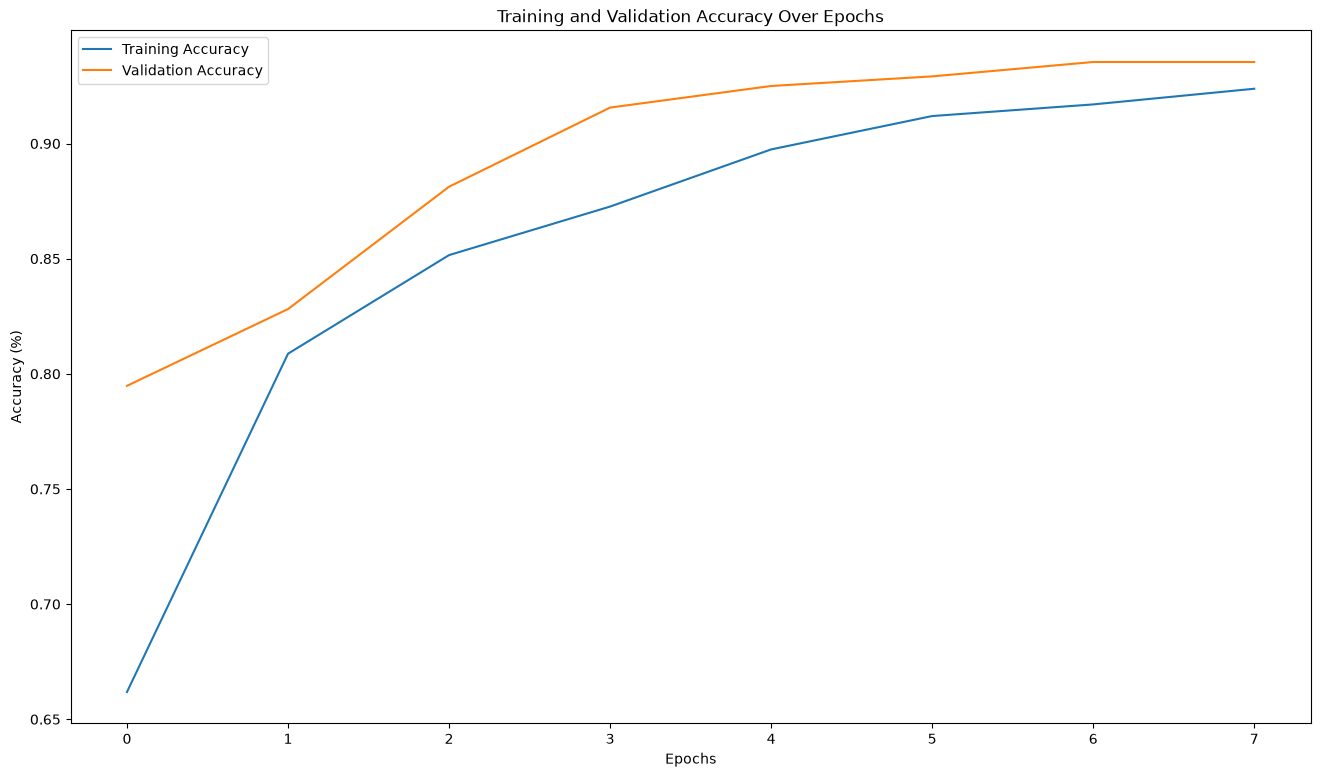

In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_range = range(len(acc))
plt.figure(figsize=(16, 9))
plt.plot(epoch_range, acc, label='Training Accuracy')
plt.plot(epoch_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()